# SRAM General Tract Characteristics Data.csv

Executed source EDA. Only aggregate outputs are retained. Public inputs remain local. No causal inference or attendance model is used.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'public/data/manifest.json').exists())
manifest = json.loads((ROOT/'public/data/manifest.json').read_text())
areas = pd.read_json(ROOT/'public/data/areas.json')
counties = {c + ' County' for c in manifest['geography']}
print('Mode:', manifest['mode'], '| Version:', manifest['datasetVersion'])


Mode: observed | Version: 5d7db3d37ab5


National/multiregion rows before filtering: 84119
Study-area rows: 490


POP2020        0
OHU2020        0
PovertyRate    2
Name: missing, dtype: int64

,POP2020,OHU2020,PovertyRate
count,490.000000,490.000000,488.000000
mean,5455.869388,2019.089796,12.195697
std,2602.950163,902.665270,8.296953
min,0.000000,0.000000,0.600000
25%,3637.250000,1420.250000,6.200000
50%,5093.500000,1899.500000,10.000000
75%,6752.250000,2507.750000,17.025000
max,18656.000000,6609.000000,58.300000


POP2020        17
OHU2020        13
PovertyRate     8
Name: IQR outliers; inspect, do not delete automatically, dtype: int64

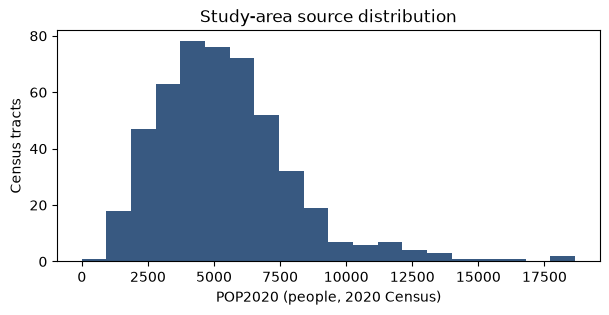

In [2]:
df = pd.read_csv(ROOT/'data/raw/SRAM General Tract Characteristics Data.csv', dtype=str, encoding='cp1252')
print('National/multiregion rows before filtering:', len(df))
df = df[(df.State == 'Florida') & df.County20.isin(counties)].copy()
columns = ['POP2020', 'OHU2020', 'PovertyRate']
values = df[columns].apply(pd.to_numeric, errors='coerce')
print('Study-area rows:', len(df))
display(values.isna().sum().rename('missing'))
display(values.describe())
q1, q3 = values.quantile(.25), values.quantile(.75)
display(((values < q1 - 1.5*(q3-q1)) | (values > q3 + 1.5*(q3-q1))).sum().rename('IQR outliers; inspect, do not delete automatically'))
fig, ax = plt.subplots(figsize=(7,3))
values[columns[0]].dropna().hist(ax=ax,bins=20,color='#385981',grid=False)
ax.set(xlabel='POP2020 (people, 2020 Census)',ylabel='Census tracts',title='Study-area source distribution')
plt.show()


## Interpretation and limitations

The displayed row counts and missingness are observed from these local files. Numeric outliers are retained unless a documented source error exists. Statistical geography is the census tract; retailer locations are points, not service coverage. Estimates have mixed vintages and cannot establish individual need, travel time, attendance, or causal impact. ACS poverty/SNAP sentinel values remain missing. Tract-level associations do not describe individual households. The 2020 geometry joins by exact GEOID, never by tract label. See `docs/data_audit.md` and `docs/transformations.md` for exclusions and lineage.